Carga y conjuntos

In [1]:
import sys
sys.path.append('../')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.caracteristicas import conjuntos_de_features
from src.modelos import *

df_feat = pd.read_csv('../data/processed/features.csv')
cols_feat = [c for c in df_feat.columns if c.startswith(('est_', 'psd_', 'wav_', 'stft_'))]
y = df_feat['etiqueta'].values
grupos = df_feat['archivo'].values

todos = conjuntos_de_features(cols_feat)
conjuntos = {
    'B_espectral_clasico': todos['B_espectral_clasico'],     # 23 características
    'C_tiempo_frecuencia': todos['C_tiempo_frecuencia'],     # 40 características
    'C_top23': todos['C_tiempo_frecuencia'],                 # control: C con solo sus 23 mejores (igual número que B)
}
k_por_conjunto = {'C_top23': len(todos['B_espectral_clasico'])}
print({k: len(v) for k, v in todos.items()})

{'A_estadisticas': 10, 'B_espectral_clasico': 23, 'C_tiempo_frecuencia': 40, 'D_todo': 53}


validación con 10 semillas

In [2]:
res, oof = comparar_semillas(df_feat, y, grupos, conjuntos, k_por_conjunto=k_por_conjunto,
                             n_splits=5, semillas=range(10))
res.to_csv('../data/processed/resultados_fase6.csv', index=False)
resumen_semillas(res)     # media ± desviación sobre 50 pares semilla×fold

,sensibilidad,especificidad,f1,auc
conjunto,,,,
B_espectral_clasico,0.97 ± 0.022,0.982 ± 0.012,0.951 ± 0.02,0.996 ± 0.003
C_tiempo_frecuencia,0.98 ± 0.016,0.988 ± 0.009,0.967 ± 0.018,0.998 ± 0.002
C_top23,0.984 ± 0.017,0.983 ± 0.011,0.96 ± 0.021,0.998 ± 0.002


Prueba de Wilcoxon

In [3]:
print("C (tiempo-frecuencia) vs B (espectral clásico):")
display(wilcoxon_pareado(res, 'B_espectral_clasico', 'C_tiempo_frecuencia'))
print("Control con el mismo número de características: C_top23 vs B:")
display(wilcoxon_pareado(res, 'B_espectral_clasico', 'C_top23')[['metrica', 'media_a', 'media_b', 'diferencia', 'p_wilcoxon']])

C (tiempo-frecuencia) vs B (espectral clásico):


,metrica,media_a,media_b,diferencia,pares_b_gana,pares_empate,pares_a_gana,n_pares,p_wilcoxon
0,sensibilidad,0.9705,0.9797,0.0092,32,8,10,50,1.840000e-04
1,especificidad,0.9819,0.9883,0.0063,39,6,5,50,4.210000e-08
2,f1,0.9506,0.9671,0.0165,46,1,3,50,2.470000e-09
3,auc,0.9963,0.9982,0.0019,48,1,1,50,1.260000e-09


Control con el mismo número de características: C_top23 vs B:


,metrica,media_a,media_b,diferencia,p_wilcoxon
0,sensibilidad,0.9705,0.9842,0.0137,1.580000e-07
1,especificidad,0.9819,0.9835,0.0015,2.160000e-01
2,f1,0.9506,0.9604,0.0099,6.830000e-05
3,auc,0.9963,0.9978,0.0015,1.860000e-04


intervalos de confianza al 95 %

In [4]:
puntajes = {k: oof[k] for k in ['B_espectral_clasico', 'C_tiempo_frecuencia']}
tabla_ic, tabla_dif = bootstrap_por_archivo(y, grupos, puntajes, n_boot=2000)
display(tabla_ic)
print("Diferencia C − B con IC95 % (remuestreo de archivos):")
display(tabla_dif)

,conjunto,metrica,estimado,ic95_inf,ic95_sup
0,B_espectral_clasico,sensibilidad,0.9630,0.9305,0.9879
1,B_espectral_clasico,especificidad,0.9818,0.9691,0.9925
2,B_espectral_clasico,f1,0.9460,0.9169,0.9712
3,B_espectral_clasico,auc,0.9950,0.9906,0.9985
4,C_tiempo_frecuencia,sensibilidad,0.9770,0.9515,0.9948
5,C_tiempo_frecuencia,especificidad,0.9875,0.9783,0.9952
6,C_tiempo_frecuencia,f1,0.9640,0.9411,0.9819
7,C_tiempo_frecuencia,auc,0.9975,0.9945,0.9995


Diferencia C − B con IC95 % (remuestreo de archivos):


,metrica,diferencia,ic95_inf,ic95_sup,p_bootstrap,ic_excluye_cero
0,sensibilidad,0.0140,-0.0041,0.0368,0.173,False
1,especificidad,0.0058,0.0010,0.0109,0.015,True
2,f1,0.0180,0.0050,0.0332,0.004,True
3,auc,0.0025,0.0008,0.0044,0.001,True


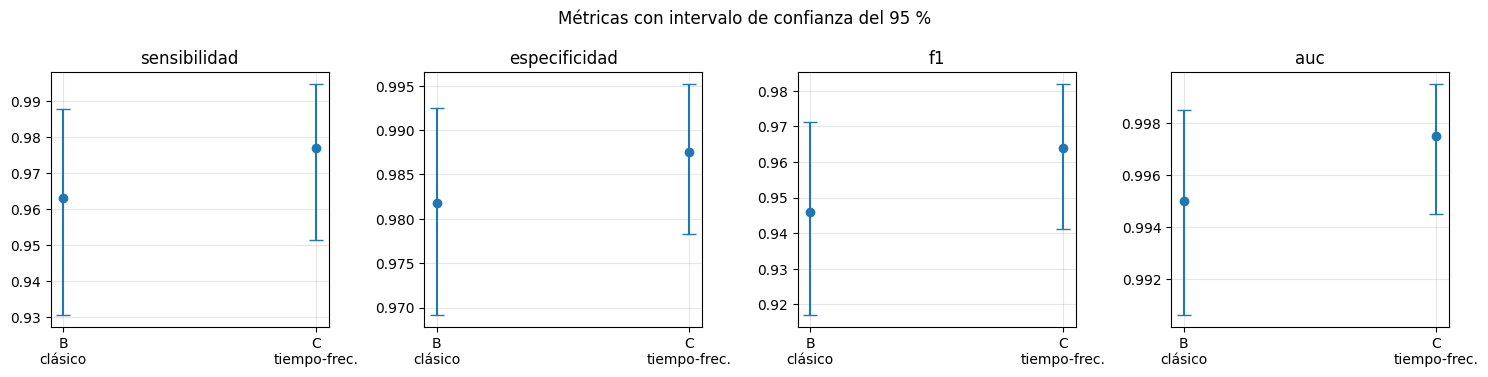

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=False)
for ax, m in zip(axes, ['sensibilidad', 'especificidad', 'f1', 'auc']):
    sub = tabla_ic[tabla_ic.metrica == m]
    est, lo, hi = sub['estimado'].values, sub['ic95_inf'].values, sub['ic95_sup'].values
    ax.errorbar(range(len(sub)), est, yerr=[est - lo, hi - est], fmt='o', capsize=5)
    ax.set_xticks(range(len(sub))); ax.set_xticklabels(['B\nclásico', 'C\ntiempo-frec.']); ax.set_title(m); ax.grid(alpha=0.3)
plt.suptitle('Métricas con intervalo de confianza del 95 %'); plt.tight_layout()
plt.savefig('../figuras/metricas_con_IC.png', dpi=200, bbox_inches='tight'); plt.show()

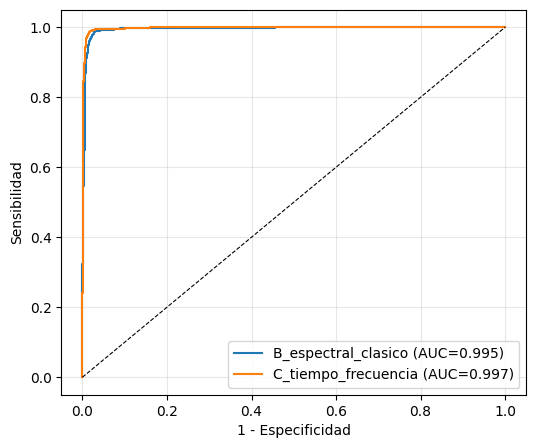

B_espectral_clasico -> especificidad alcanzable con sensibilidad mínima: {'sens>=90%': 0.9918, 'sens>=95%': 0.9858, 'sens>=99%': 0.9692}
C_tiempo_frecuencia -> especificidad alcanzable con sensibilidad mínima: {'sens>=90%': 0.995, 'sens>=95%': 0.992, 'sens>=99%': 0.9775}


In [6]:
roc = curvas_roc(df_feat[cols_feat], y, grupos, {k: todos[k] for k in ['B_espectral_clasico', 'C_tiempo_frecuencia']}, semilla=0)
plt.figure(figsize=(6, 5))
for n, (fpr, tpr, auc) in roc.items():
    plt.plot(fpr, tpr, label=f'{n} (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=0.8); plt.xlabel('1 - Especificidad'); plt.ylabel('Sensibilidad'); plt.legend(); plt.grid(alpha=0.3)
plt.savefig('../figuras/roc_fase6.png', dpi=200, bbox_inches='tight'); plt.show()

for n in ['B_espectral_clasico', 'C_tiempo_frecuencia']:
    print(n, '-> especificidad alcanzable con sensibilidad mínima:', especificidad_a_sensibilidad(y, oof[n]))